# v2 · 01 · Expected extra loss and "what would change the decision"
Two additions to the v1 credit-increase scenario (v1 files are untouched; this notebook only reads v1 outputs):
1. **Expected extra loss**: how much money the hypothetical increase would put at risk, using the customer's *own* behaviour.
2. **What would change the decision**: the largest request that would still be supportable, and how much of their bill the customer would need to pay.

> Demonstrative scenario analysis, not a lending policy. The requested increase is hypothetical.

**Setup.**

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))      # v2 package (adds v1 src to the path too)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from credit_kg_v2 import load_config, OUT
from credit_kg import config as C, scoring as S, modeling as M
from credit_kg_v2 import scenario_plus as SP
cfg = S.load_config(); v2cfg = load_config()

**Assumptions, stated up front.**
* The default probability does not change because of the increase (the data cannot tell us this).
* The customer will use the new headroom the way they used their card before: their **typical (median) utilization**.
* If they default, the share of the drawn amount that is lost (LGD) is set in `config_v2.yaml`. The data has no recovery information, so we use a conservative 1.0.

In [2]:
print("LGD assumption:", v2cfg["expected_loss"]["lgd"])

LGD assumption: 1.0


**Load the v1 scoring inputs** (behaviour features, calibrated default probability, graph features) and add each customer's typical utilization.

In [3]:
inp = S.load_scoring_inputs()
wide = pd.read_parquet(C.PROCESSED / "customers.parquet")
inp = inp.merge(wide[["customer_id"]].assign(typical_util=SP.typical_utilization(wide).to_numpy()), on="customer_id")
inp[["pd", "typical_util", "bill_latest", "pay_median"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
pd,30000.0,0.222,0.200,0.0,0.090,0.149,0.267,1.0
typical_util,30000.0,0.368,0.358,0.0,0.017,0.263,0.701,1.0
bill_latest,30000.0,51223.331,73635.861,-165580.0,3558.750,22381.500,67091.000,964511.0
pay_median,30000.0,3287.268,7134.277,0.0,725.375,1750.000,3950.000,747276.0


**Scenario: each customer asks for 3 × their own typical monthly payment** (a relative request). We score it with the v1 score and add the expected extra loss.

In [4]:
R = S.relative_increase(inp, "payment_multiple", 3)
res = S.score(inp, R, cfg)
el = SP.expected_loss(inp, R)
scen = inp[["customer_id", "pd", "pay_median", "credit_limit", "typical_util"]].join(res[["score", "band"]]).join(el.drop(columns="customer_id"))
scen[["el_requested_increase", "el_expected_extra_drawn", "el_extra_expected_loss", "el_extra_loss_in_payment_months"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
el_requested_increase,30000.0,9861.81,21402.83,0.0,2176.12,5250.00,11850.00,2241828.00
el_expected_extra_drawn,30000.0,4116.13,11006.05,0.0,53.06,1408.96,4687.46,1261601.89
el_extra_expected_loss,30000.0,839.49,2118.97,0.0,6.98,141.93,784.83,82160.70
el_extra_loss_in_payment_months,26262.0,0.33,0.49,0.0,0.01,0.10,0.41,2.41


**Expected extra loss by band.** If the score makes sense, the 'supportable' band should carry much less expected extra loss per customer than 'not supportable'.

In [5]:
order = [S.BAND_SUPPORT, S.BAND_REVIEW, S.BAND_NOT, S.BAND_INSUFFICIENT]
by_band = scen.groupby("band").agg(customers=("customer_id", "size"), mean_pd=("pd", "mean"),
                                   median_extra_loss=("el_extra_expected_loss", "median"),
                                   total_extra_loss=("el_extra_expected_loss", "sum"),
                                   median_loss_in_payment_months=("el_extra_loss_in_payment_months", "median")).reindex(order)
by_band["share_of_total_extra_loss"] = by_band.total_extra_loss / by_band.total_extra_loss.sum()
by_band.to_csv(OUT / "expected_loss_by_band.csv"); by_band.round(3)

,customers,mean_pd,median_extra_loss,total_extra_loss,median_loss_in_payment_months,share_of_total_extra_loss
band,,,,,,
Supportable in this scenario,18758,0.115,176.779,1.029284e+07,0.067,0.409
Review,1651,0.324,906.227,2.387300e+06,0.607,0.095
Not supportable in this scenario,4286,0.643,1599.638,1.250005e+07,1.315,0.496
Insufficient behavioural evidence,5305,0.228,0.000,4.640454e+03,0.002,0.000


**Absolute vs relative request, in money at risk.** The same 30,000 for everyone vs 3 × own typical payment: total expected extra loss, split by band.

,"same 30,000 for everyone",3 × own typical payment
band,,
Supportable in this scenario,11.56,10.29
Review,18.18,2.39
Not supportable in this scenario,58.48,12.50
Insufficient behavioural evidence,0.99,0.00


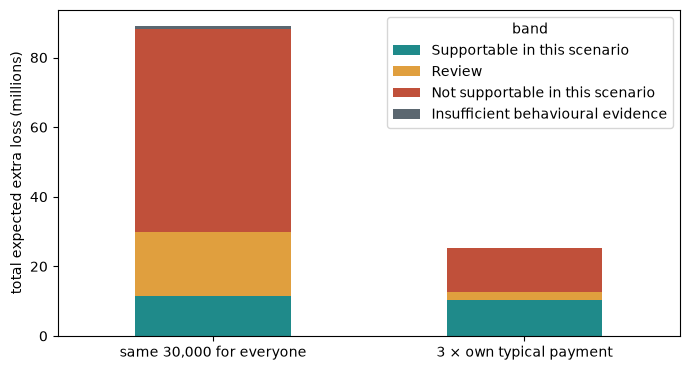

In [6]:
el_abs = SP.expected_loss(inp, 30000).join(S.score(inp, 30000, cfg)["band"])
el_rel = el.join(res["band"])
cmp = pd.DataFrame({"same 30,000 for everyone": el_abs.groupby("band")["el_extra_expected_loss"].sum(),
                    "3 × own typical payment": el_rel.groupby("band")["el_extra_expected_loss"].sum()}).reindex(order)
ax = (cmp / 1e6).T.plot(kind="bar", stacked=True, figsize=(7, 3.8), color=["#1F8A8A", "#E09F3E", "#C0503A", "#5B6770"])
ax.set_ylabel("total expected extra loss (millions)"); ax.set_xlabel(""); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT / "expected_loss_abs_vs_rel.png", dpi=120); (cmp / 1e6).round(2)

**What would change the decision? Lever 1: request size.** For every customer, the largest hypothetical increase that would still be "supportable" (binary search; the score always falls as the request grows, so the boundary is exact).
We also express it in the customer's own units: months of their typical payment.

In [7]:
mx = SP.max_supportable_increase(inp, cfg)
inp["max_supportable_increase"] = mx
inp["max_supportable_in_payment_months"] = np.where(inp.pay_median > 0, mx / inp.pay_median.where(inp.pay_median > 0, 1), np.nan)
print(f"customers with some supportable request: {mx.notna().mean():.1%}")
inp[["max_supportable_increase", "max_supportable_in_payment_months"]].describe(percentiles=[.1, .25, .5, .75, .9]).T.round(1)

customers with some supportable request: 63.7%


,count,mean,std,min,10%,25%,50%,75%,90%,max
max_supportable_increase,19122.0,147351.3,218984.4,3.6,10062.1,22128.1,60025.8,154161.7,432164.8,2340000.0
max_supportable_in_payment_months,19122.0,202.8,10564.3,1.0,8.0,11.7,20.1,29.7,108.6,1338695.1


**Lever 2: payment coverage.** For customers whose 3× request is *not* supportable: what share of each previous bill would they need to pay to make it supportable, keeping everything else the same?

In [8]:
cov = SP.coverage_needed(inp, R, cfg)
not_supp = res["band"] != S.BAND_SUPPORT
gated = res["gate"] != ""
summary = pd.Series({
    "not supportable or review": int(not_supp.sum()),
    "  blocked by a gate (levers cannot help)": int((not_supp & gated).sum()),
    "  fixable by paying more of each bill": int((not_supp & ~gated & np.isfinite(cov)).sum()),
    "  not fixable by coverage alone": int((not_supp & ~gated & np.isinf(cov)).sum())}, name="customers")
inp["coverage_needed"] = cov
summary.to_frame()

,customers
not supportable or review,11242
blocked by a gate (levers cannot help),8932
fixable by paying more of each bill,943
not fixable by coverage alone,1367


**How big a change is needed?** For customers who could get there by paying more of their bills: their current coverage vs the coverage needed.

In [9]:
fx = inp[not_supp & ~gated & np.isfinite(cov)]
pd.DataFrame({"current coverage": fx.coverage_median.describe(percentiles=[.25, .5, .75]),
              "coverage needed": fx.coverage_needed.describe(percentiles=[.25, .5, .75])}).round(2)

,current coverage,coverage needed
count,943.00,943.00
mean,0.07,0.32
std,0.07,0.27
min,0.00,0.01
25%,0.04,0.08
50%,0.05,0.24
75%,0.07,0.46
max,0.63,0.98


**Plain-language levers for three real customers** in the Review band (request = 3 × their typical payment).

In [10]:
examples = inp[(res["band"] == S.BAND_REVIEW)].sample(3, random_state=C.SEED)
for _, r in examples.iterrows():
    one = inp[inp.customer_id == r.customer_id]
    req = float(S.relative_increase(one, "payment_multiple", 3).iloc[0])
    print(f"Customer {int(r.customer_id)} | request {req:,.0f} | score {S.score(one, req, cfg).score.iloc[0]:.0f} | "
          f"extra expected loss {SP.expected_loss(one, req).el_extra_expected_loss.iloc[0]:,.0f}")
    for m in SP.what_would_change(one, req, cfg): print("   -", m)

Customer 9116 | request 3,000 | score 69 | extra expected loss 669


   - A request of up to 2,041 (instead of 3,000) would be supportable.
   - Paying about 12% of each previous bill (now 8%) would make this request supportable.
Customer 1272 | request 3,009 | score 52 | extra expected loss 1,109


   - No single lever (request size or payment coverage) is enough; the risk profile dominates.
Customer 16354 | request 4,698 | score 68 | extra expected loss 482


   - A request of up to 2,143 (instead of 4,698) would be supportable.
   - Paying about 9% of each previous bill (now 5%) would make this request supportable.


**Save** the per-customer v2 scenario table.

In [11]:
inp[["customer_id", "max_supportable_increase", "max_supportable_in_payment_months", "coverage_needed"]].join(
    el.drop(columns="customer_id")).to_parquet(OUT / "v2_scenario_levers_3x_payment.parquet", index=False); print("saved")

saved


### Takeaways
* **Money at risk follows the bands.** With a request of 3 × own typical payment, the 4,286 "not supportable" customers carry **half** of all expected extra loss (12.5M of 25.2M), while the 18,758 "supportable" customers carry 41%. Median extra loss per customer is ~177 (supportable) vs ~1,600 (not supportable).
* **Relative requests put far less money at risk in the risky band.** Same 30,000 for everyone: 58.5M expected extra loss sits in "not supportable"; 3 × own typical payment: 12.5M. Sizing requests to each customer's own scale avoids handing large amounts to the riskiest customers.
* **What would change the decision:**
  - 63.7% of customers have *some* supportable request (median: ~20 months of their own typical payment);
  - of the 11,242 not supportable or review at 3×: 8,932 are blocked by a gate (no lever helps), 943 could get there by paying more of each bill (median from 5% to ~24% of the bill), and 1,367 cannot get there by coverage alone.
* **Assumptions:** PD unchanged by the increase; new headroom used at the customer's typical utilization; LGD = 1.0 (conservative, configurable).